# Notebook 6 — Temporal Ablation and Multi-Seed Evaluation

## Goal

Notebook 5 produced one CNN + LSTM run per TTE. This notebook makes that result defensible by answering
the proposal's secondary question:

> Is the learned model genuinely using **temporal** information, or is it just recognising static scene appearance?

All variants use the **same cached ResNet-18 features** `(16, 512)` per clip, the same clips and the
same validation videos as Notebooks 4 and 5. Only the temporal handling differs.

| Variant | What it tests |
|---|---|
| `lstm` | The Notebook 5 model (frame order preserved). |
| `lstm_test_shuffled` | The *trained* LSTM is given shuffled frames at test time. Does it rely on order? |
| `lstm_train_shuffled` | An LSTM is trained **and** tested on shuffled frames. Can it still learn without order? |
| `mean_pool` | Mean of the 16 frame features, then an MLP. Uses all frames but has **no temporal modelling**. |
| `last_frame` | Only the final frame (the one closest to the prediction time) is used. A single static image. |
| `optical_flow` | The scaled optical-flow logistic regression from Notebook 4 (refitted here so every model is scored identically). |
| `naive` | Chance reference. |

## Changes to the evaluation protocol

1. **Five seeds** per variant and TTE; we report mean ± standard deviation.
2. **No model selection on the validation set.** Notebook 5 kept the epoch with the best *validation* AP and then
   reported that same validation AP, which is slightly optimistic. Here 20% of the *training* videos are held out as an
   inner validation set to choose the epoch, and the official validation set is only scored once per run.
   (The oracle best-validation-epoch AP is still logged as `oracle_val_AP` for comparison with Notebook 5.)
3. **Recall at a fixed false-alarm rate** is added, as promised in the proposal.
4. **Bootstrap confidence intervals** over validation clips. Seeds capture training noise only; with 300 validation
   clips the sampling noise of AP is much larger, and it is what matters for comparing models.

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, roc_curve,
    precision_score, recall_score, f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## 1. Configuration

In [2]:
PROCESSED_DIR = Path("./data/processed")
FEATURE_DIR = PROCESSED_DIR / "cnn_features"
RESULTS_DIR = Path("./results")
FIGURE_DIR = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

TTE_VALUES = [0.5, 1.0, 1.5]
SEEDS = [42, 43, 44, 45, 46]

NUM_EPOCHS = int(os.environ.get("NUM_EPOCHS", 10))   # 10 = Notebook 5 setting; override to test under-training
TAG = "" if NUM_EPOCHS == 10 else f"_{NUM_EPOCHS}ep"  # keeps longer runs from overwriting the default outputs
BATCH_SIZE = 32          # same as Notebook 5
LEARNING_RATE = 1e-3     # same as Notebook 5
HIDDEN_SIZE = 128        # same as Notebook 5
FEATURE_DIM = 512

INNER_VAL_FRACTION = 0.2
INNER_SPLIT_SEED = 42
N_TEST_SHUFFLES = 10     # shuffles averaged for the test-time-shuffle evaluation
N_BOOTSTRAP = 2000
BOOTSTRAP_SEED = 0
FPR_TARGETS = (0.10, 0.20)

DEVICE = torch.device("cpu")  # the cached features make GPU unnecessary
torch.set_num_threads(4)
print("Device:", DEVICE, "| torch", torch.__version__)

Device: cpu | torch 2.13.0+cpu


## 2. Load cached features and labels

Labels come from the fixed clip metadata, in the same row order used when the features were cached.
We also check that the clip order is identical across TTEs (needed for paired comparisons) and that the
labels agree with the optical-flow arrays from Notebook 4.

In [3]:
train_clips = pd.read_csv(PROCESSED_DIR / "train_clips.csv")
val_clips = pd.read_csv(PROCESSED_DIR / "val_clips.csv")

X_train, y_train, X_val, y_val = {}, {}, {}, {}
val_ids = {}

for tte in TTE_VALUES:
    tr = train_clips[train_clips["tte"] == tte].reset_index(drop=True)
    va = val_clips[val_clips["tte"] == tte].reset_index(drop=True)

    X_train[tte] = np.load(FEATURE_DIR / f"train_tte_{tte}.npy")
    X_val[tte] = np.load(FEATURE_DIR / f"val_tte_{tte}.npy")
    y_train[tte] = tr["target"].to_numpy().astype(int)
    y_val[tte] = va["target"].to_numpy().astype(int)
    val_ids[tte] = va["id"].astype(float).astype(int).to_numpy()

    assert len(X_train[tte]) == len(y_train[tte]) and len(X_val[tte]) == len(y_val[tte])
    # Labels must match the optical-flow arrays built in Notebook 4.
    assert np.array_equal(y_train[tte], np.load(PROCESSED_DIR / f"y_train_flow_tte_{tte}.npy").astype(int))
    assert np.array_equal(y_val[tte], np.load(PROCESSED_DIR / f"y_val_flow_tte_{tte}.npy").astype(int))
    print(f"TTE {tte}: train {X_train[tte].shape}, val {X_val[tte].shape}, "
          f"val positives {y_val[tte].sum()}")

for tte in TTE_VALUES[1:]:
    assert np.array_equal(val_ids[tte], val_ids[TTE_VALUES[0]]), "validation clip order differs across TTEs"
print("Validation videos are identical and identically ordered across TTEs.")

TTE 0.5: train (1200, 16, 512), val (300, 16, 512), val positives 150
TTE 1.0: train (1200, 16, 512), val (300, 16, 512), val positives 150
TTE 1.5: train (1199, 16, 512), val (300, 16, 512), val positives 150
Validation videos are identical and identically ordered across TTEs.


## 3. Inner train / inner validation split

Within a TTE every video appears exactly once, so splitting clips splits videos. The inner split is
stratified and fixed, so seeds only change initialisation and batch order.

In [4]:
inner = {}
for tte in TTE_VALUES:
    idx = np.arange(len(y_train[tte]))
    fit_idx, sel_idx = train_test_split(
        idx, test_size=INNER_VAL_FRACTION, stratify=y_train[tte], random_state=INNER_SPLIT_SEED
    )
    inner[tte] = (fit_idx, sel_idx)
    print(f"TTE {tte}: fit {len(fit_idx)} | epoch-selection {len(sel_idx)}")

TTE 0.5: fit 960 | epoch-selection 240
TTE 1.0: fit 960 | epoch-selection 240
TTE 1.5: fit 959 | epoch-selection 240


## 4. Metrics

* **AP** (AUPRC) is the primary metric.
* **Recall @ FPR** is the best recall achievable while keeping the false-alarm rate at or below the target,
  i.e. a threshold-free operating-point metric. With 150 validation negatives, FPR ≤ 0.10 means at most 15 false alarms.
* Precision / Recall / F1 use the fixed 0.5 threshold, as in Notebooks 4 and 5.

In [5]:
def recall_at_fpr(y_true, score, fpr_target):
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(tpr[fpr <= fpr_target].max())


def compute_metrics(y_true, prob):
    pred = (prob >= 0.5).astype(int)
    out = {
        "AP": average_precision_score(y_true, prob),
        "ROC_AUC": roc_auc_score(y_true, prob),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
    }
    for target in FPR_TARGETS:
        out[f"Recall@FPR{int(target * 100)}"] = recall_at_fpr(y_true, prob, target)
    return out


METRIC_COLUMNS = ["AP", "ROC_AUC", "Recall@FPR10", "Recall@FPR20", "Precision", "Recall", "F1"]

## 5. Models

`CNNLSTM` is identical to Notebook 5. The two non-temporal controls are small MLPs of comparable depth:
they see the same features but cannot use frame order (`mean_pool`) or any frame but the last (`last_frame`).

In [6]:
class CNNLSTM(nn.Module):
    def __init__(self, input_size=FEATURE_DIM, hidden_size=HIDDEN_SIZE):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, num_layers=1, batch_first=True)
        self.classifier = nn.Linear(hidden_size, 1)

    def forward(self, x):
        _, (hidden_state, _) = self.lstm(x)
        return self.classifier(hidden_state[-1]).squeeze(1)


class MeanPoolMLP(nn.Module):
    """Order-invariant: average the 16 frame features, then classify."""
    def __init__(self, input_size=FEATURE_DIM, hidden_size=HIDDEN_SIZE):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(input_size, hidden_size), nn.ReLU(), nn.Linear(hidden_size, 1))

    def forward(self, x):
        return self.net(x.mean(dim=1)).squeeze(1)


class LastFrameMLP(nn.Module):
    """Static image control: only the frame closest to the prediction time."""
    def __init__(self, input_size=FEATURE_DIM, hidden_size=HIDDEN_SIZE):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(input_size, hidden_size), nn.ReLU(), nn.Linear(hidden_size, 1))

    def forward(self, x):
        return self.net(x[:, -1]).squeeze(1)


MODEL_FACTORY = {
    "lstm": CNNLSTM,
    "lstm_train_shuffled": CNNLSTM,
    "mean_pool": MeanPoolMLP,
    "last_frame": LastFrameMLP,
}
for name, factory in MODEL_FACTORY.items():
    print(f"{name:22s} parameters: {sum(p.numel() for p in factory().parameters()):,}")

lstm                   parameters: 328,833
lstm_train_shuffled    parameters: 328,833
mean_pool              parameters: 65,793
last_frame             parameters: 65,793


## 6. Frame shuffling

Each clip's 16 frames are permuted independently. A permutation can leave a clip unchanged by chance
(probability 1/16!), which is negligible.

In [7]:
def shuffle_frames(X, rng):
    order = np.argsort(rng.random(X.shape[:2]), axis=1)
    return np.take_along_axis(X, order[:, :, None], axis=1)

## 7. Training one run

Adam, BCE-with-logits, 10 epochs, exactly as in Notebook 5, but trained on the 80% inner-train split.
The epoch is chosen by **inner-validation AP**. The official validation set is scored every epoch only so
that the oracle/final-epoch numbers can be logged; it is never used to choose anything.

In [8]:
def predict_prob(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.as_tensor(X, dtype=torch.float32))).numpy()


def train_run(kind, tte, seed):
    fit_idx, sel_idx = inner[tte]
    Xfit, yfit = X_train[tte][fit_idx], y_train[tte][fit_idx]
    Xsel, ysel = X_train[tte][sel_idx], y_train[tte][sel_idx]
    Xval, yval = X_val[tte], y_val[tte]

    if kind == "lstm_train_shuffled":
        rng = np.random.default_rng(seed)
        Xfit, Xsel, Xval = (shuffle_frames(a, rng) for a in (Xfit, Xsel, Xval))

    torch.manual_seed(seed)
    np.random.seed(seed)
    model = MODEL_FACTORY[kind]().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.BCEWithLogitsLoss()

    Xfit_t = torch.as_tensor(Xfit, dtype=torch.float32)
    yfit_t = torch.as_tensor(yfit, dtype=torch.float32)

    history, states = [], []
    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        perm = torch.randperm(len(Xfit_t))
        total_loss = 0.0
        for start in range(0, len(perm), BATCH_SIZE):
            batch = perm[start:start + BATCH_SIZE]
            optimizer.zero_grad()
            loss = criterion(model(Xfit_t[batch]), yfit_t[batch])
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(batch)

        val_prob = predict_prob(model, Xval)
        history.append({
            "epoch": epoch,
            "train_loss": total_loss / len(Xfit_t),
            "inner_AP": average_precision_score(ysel, predict_prob(model, Xsel)),
            "val_AP": average_precision_score(yval, val_prob),
            "val_prob": val_prob,
        })
        states.append({k: v.clone() for k, v in model.state_dict().items()})

    selected = int(np.argmax([h["inner_AP"] for h in history]))   # first maximum
    return model, states[selected], history, selected

## 8. Run every variant, TTE and seed

Everything runs on cached features, so this takes a few minutes on CPU.

In [9]:
rows, val_probs, histories = [], {}, {}
t0 = time.time()

for tte in TTE_VALUES:
    for kind in ["lstm", "lstm_train_shuffled", "mean_pool", "last_frame"]:
        for seed in SEEDS:
            model, best_state, history, selected = train_run(kind, tte, seed)
            chosen = history[selected]
            yval = y_val[tte]

            rows.append({
                "variant": kind, "tte": tte, "seed": seed, "selected_epoch": chosen["epoch"],
                **compute_metrics(yval, chosen["val_prob"]),
                "final_epoch_val_AP": history[-1]["val_AP"],
                "oracle_val_AP": max(h["val_AP"] for h in history),
            })
            val_probs.setdefault((kind, tte), []).append(chosen["val_prob"])
            histories[(kind, tte, seed)] = pd.DataFrame(history).drop(columns="val_prob")

            # Test-time shuffle of the *trained, order-aware* LSTM.
            if kind == "lstm":
                model.load_state_dict(best_state)
                rng = np.random.default_rng(1000 + seed)
                shuffled_probs = [predict_prob(model, shuffle_frames(X_val[tte], rng))
                                  for _ in range(N_TEST_SHUFFLES)]
                per_shuffle = [compute_metrics(yval, p) for p in shuffled_probs]
                mean_prob = np.mean(shuffled_probs, axis=0)
                rows.append({
                    "variant": "lstm_test_shuffled", "tte": tte, "seed": seed,
                    "selected_epoch": chosen["epoch"],
                    **{m: float(np.mean([r[m] for r in per_shuffle])) for m in METRIC_COLUMNS},
                    "final_epoch_val_AP": np.nan, "oracle_val_AP": np.nan,
                })
                val_probs.setdefault(("lstm_test_shuffled", tte), []).append(mean_prob)

        print(f"TTE {tte} | {kind:20s} done  ({(time.time() - t0) / 60:.1f} min)")

TTE 0.5 | lstm                 done  (0.2 min)


TTE 0.5 | lstm_train_shuffled  done  (0.4 min)


TTE 0.5 | mean_pool            done  (0.4 min)


TTE 0.5 | last_frame           done  (0.4 min)


TTE 1.0 | lstm                 done  (0.6 min)


...

TTE 1.0 | last_frame           done  (0.8 min)


TTE 1.5 | lstm                 done  (1.0 min)


TTE 1.5 | lstm_train_shuffled  done  (1.1 min)


TTE 1.5 | mean_pool            done  (1.2 min)


TTE 1.5 | last_frame           done  (1.2 min)


## 9. Baselines scored with the same metrics

* **Optical flow**: the Notebook 4 pipeline (StandardScaler + logistic regression) refitted on the saved
  flow features. It is deterministic, so there is one run. We assert that it reproduces the saved
  `baseline_results.csv` to within 0.005 AP. It is not bit-identical: the saved numbers came from a different
  Python/scikit-learn build, and the logistic-regression solver differs by about 1e-3 across environments.
  The refit values are used here so that every model is scored by the same code on the same machine.
* **Naive**: a constant score. Its recall at a fixed FPR equals that FPR (random chance); this is a reference
  value rather than a measured one.

In [10]:
saved_baselines = pd.read_csv(RESULTS_DIR / "baseline_results.csv")

for tte in TTE_VALUES:
    Xtr = np.load(PROCESSED_DIR / f"X_train_flow_tte_{tte}.npy")
    ytr = np.load(PROCESSED_DIR / f"y_train_flow_tte_{tte}.npy").astype(int)
    Xva = np.load(PROCESSED_DIR / f"X_val_flow_tte_{tte}.npy")

    flow = Pipeline([("scaler", StandardScaler()),
                     ("classifier", LogisticRegression(max_iter=1000, random_state=42))]).fit(Xtr, ytr)
    flow_prob = flow.predict_proba(Xva)[:, 1]

    flow_metrics = compute_metrics(y_val[tte], flow_prob)
    saved = saved_baselines[(saved_baselines["model"] == "optical_flow_scaled") & (saved_baselines["tte"] == tte)].iloc[0]
    gap = abs(flow_metrics["AP"] - saved["AP"])
    print(f"Optical flow TTE {tte}: refit AP {flow_metrics['AP']:.4f} vs saved {saved['AP']:.4f} (|diff| {gap:.4f})")
    assert gap < 5e-3, "optical-flow refit does not reproduce the saved result"

    rows.append({"variant": "optical_flow", "tte": tte, "seed": 0, "selected_epoch": np.nan, **flow_metrics,
                 "final_epoch_val_AP": np.nan, "oracle_val_AP": np.nan})
    val_probs[("optical_flow", tte)] = [flow_prob]

    naive_metrics = compute_metrics(y_val[tte], np.ones(len(y_val[tte])))
    for target in FPR_TARGETS:
        naive_metrics[f"Recall@FPR{int(target * 100)}"] = target   # chance reference
    rows.append({"variant": "naive", "tte": tte, "seed": 0, "selected_epoch": np.nan, **naive_metrics,
                 "final_epoch_val_AP": np.nan, "oracle_val_AP": np.nan})

print("Optical-flow refit matches results/baseline_results.csv within tolerance.")

runs_df = pd.DataFrame(rows)
runs_df.to_csv(RESULTS_DIR / f"temporal_ablation_runs{TAG}.csv", index=False)
print(len(runs_df), "rows saved to results/temporal_ablation_runs.csv")

Optical flow TTE 0.5: refit AP 0.5753 vs saved 0.5745 (|diff| 0.0007)
Optical flow TTE 1.0: refit AP 0.5756 vs saved 0.5758 (|diff| 0.0002)
Optical flow TTE 1.5: refit AP 0.5685 vs saved 0.5683 (|diff| 0.0002)
Optical-flow refit matches results/baseline_results.csv within tolerance.
81 rows saved to results/temporal_ablation_runs.csv


## 10. Summary across seeds (mean ± std)

In [11]:
VARIANT_ORDER = ["naive", "optical_flow", "last_frame", "mean_pool",
                 "lstm_train_shuffled", "lstm_test_shuffled", "lstm"]
DISPLAY = {
    "naive": "Naive", "optical_flow": "Optical flow", "last_frame": "Last frame (no temporal)",
    "mean_pool": "Mean-pool (no order)", "lstm_train_shuffled": "LSTM, shuffled train+test",
    "lstm_test_shuffled": "LSTM, shuffled at test only", "lstm": "CNN + LSTM",
}

grouped = runs_df.groupby(["variant", "tte"])
summary = grouped[METRIC_COLUMNS].mean().add_suffix("_mean")
summary = summary.join(grouped[METRIC_COLUMNS].std(ddof=1).add_suffix("_std"))
summary["n_seeds"] = grouped.size()
summary["selected_epoch_mean"] = grouped["selected_epoch"].mean()
summary["oracle_val_AP_mean"] = grouped["oracle_val_AP"].mean()
summary = summary.reset_index()
summary["variant"] = pd.Categorical(summary["variant"], VARIANT_ORDER, ordered=True)
summary = summary.sort_values(["tte", "variant"]).reset_index(drop=True)
summary.to_csv(RESULTS_DIR / f"temporal_ablation_summary{TAG}.csv", index=False)

table = summary[["variant", "tte", "n_seeds"]].copy()
table["variant"] = table["variant"].map(DISPLAY)
for metric in ["AP", "ROC_AUC", "Recall@FPR10", "Recall@FPR20"]:
    table[metric] = [
        f"{m:.3f} ± {s:.3f}" if n > 1 else f"{m:.3f}"
        for m, s, n in zip(summary[f"{metric}_mean"], summary[f"{metric}_std"], summary["n_seeds"])
    ]
table["selected_epoch"] = summary["selected_epoch_mean"].round(1)
table["oracle_val_AP"] = summary["oracle_val_AP_mean"].round(3)
print(table.to_string(index=False))

                    variant  tte  n_seeds            AP       ROC_AUC  Recall@FPR10  Recall@FPR20  selected_epoch  oracle_val_AP
                      Naive  0.5        1         0.500         0.500         0.100         0.200             NaN            NaN
               Optical flow  0.5        1         0.575         0.589         0.173         0.260             NaN            NaN
   Last frame (no temporal)  0.5        5 0.759 ± 0.005 0.750 ± 0.005 0.363 ± 0.024 0.527 ± 0.034             9.4          0.788
       Mean-pool (no order)  0.5        5 0.737 ± 0.007 0.713 ± 0.005 0.425 ± 0.018 0.515 ± 0.015             9.0          0.748
  LSTM, shuffled train+test  0.5        5 0.736 ± 0.012 0.717 ± 0.007 0.387 ± 0.026 0.521 ± 0.040             8.2          0.752
LSTM, shuffled at test only  0.5        5 0.728 ± 0.013 0.707 ± 0.009 0.367 ± 0.046 0.497 ± 0.030             9.4            NaN
                 CNN + LSTM  0.5        5 0.762 ± 0.019 0.750 ± 0.013 0.383 ± 0.034 0.547 ± 0.050

## 11. Bootstrap confidence intervals over validation clips

For each variant and TTE we average the validation probabilities across seeds (a seed ensemble), then resample
the 300 validation clips with replacement 2000 times. Comparisons are **paired**: the same resampled clips
score both models, so the interval reflects whether the *difference* is distinguishable from zero.
The ensemble AP can be slightly higher than the mean single-seed AP; the CIs are for the ensemble.

In [12]:
ens = {key: np.mean(probs, axis=0) for key, probs in val_probs.items()}
rng = np.random.default_rng(BOOTSTRAP_SEED)
n_val = len(y_val[TTE_VALUES[0]])
boot_idx = rng.integers(0, n_val, size=(N_BOOTSTRAP, n_val))   # same resamples for every comparison


def boot_ap(variant, tte):
    y, p = y_val[tte], ens[(variant, tte)]
    out = np.full(N_BOOTSTRAP, np.nan)
    for b, idx in enumerate(boot_idx):
        if y[idx].min() != y[idx].max():
            out[b] = average_precision_score(y[idx], p[idx])
    return out


def ci(x):
    return np.nanpercentile(x, [2.5, 97.5])


ens_variants = ["optical_flow", "last_frame", "mean_pool", "lstm_train_shuffled", "lstm_test_shuffled", "lstm"]
boot = {(v, t): boot_ap(v, t) for v in ens_variants for t in TTE_VALUES}

ci_rows = []
for v in ens_variants:
    for t in TTE_VALUES:
        lo, hi = ci(boot[(v, t)])
        ci_rows.append({"comparison": f"AP: {DISPLAY[v]}", "tte": t,
                        "estimate": average_precision_score(y_val[t], ens[(v, t)]), "ci_low": lo, "ci_high": hi})

for other in ["optical_flow", "last_frame", "mean_pool", "lstm_train_shuffled", "lstm_test_shuffled"]:
    for t in TTE_VALUES:
        diff = boot[("lstm", t)] - boot[(other, t)]
        lo, hi = ci(diff)
        est = (average_precision_score(y_val[t], ens[("lstm", t)])
               - average_precision_score(y_val[t], ens[(other, t)]))
        ci_rows.append({"comparison": f"AP diff: CNN+LSTM − {DISPLAY[other]}", "tte": t,
                        "estimate": est, "ci_low": lo, "ci_high": hi})

# Degradation with horizon (paired: the same validation videos at every TTE).
for v in ["lstm", "mean_pool", "last_frame", "optical_flow"]:
    for t_far in (1.0, 1.5):
        diff = boot[(v, 0.5)] - boot[(v, t_far)]
        lo, hi = ci(diff)
        est = (average_precision_score(y_val[0.5], ens[(v, 0.5)])
               - average_precision_score(y_val[t_far], ens[(v, t_far)]))
        ci_rows.append({"comparison": f"AP drop 0.5s→{t_far}s: {DISPLAY[v]}", "tte": t_far,
                        "estimate": est, "ci_low": lo, "ci_high": hi})

ci_df = pd.DataFrame(ci_rows)
ci_df["excludes_zero"] = (ci_df["ci_low"] > 0) | (ci_df["ci_high"] < 0)
ci_df.to_csv(RESULTS_DIR / f"temporal_ablation_bootstrap{TAG}.csv", index=False)
print(ci_df.round(3).to_string(index=False))

                                     comparison  tte  estimate  ci_low  ci_high  excludes_zero
                               AP: Optical flow  0.5     0.575   0.500    0.668           True
                               AP: Optical flow  1.0     0.576   0.495    0.660           True
                               AP: Optical flow  1.5     0.569   0.491    0.661           True
                   AP: Last frame (no temporal)  0.5     0.763   0.694    0.825           True
                   AP: Last frame (no temporal)  1.0     0.754   0.683    0.817           True
                   AP: Last frame (no temporal)  1.5     0.711   0.636    0.782           True
                       AP: Mean-pool (no order)  0.5     0.742   0.669    0.808           True
                       AP: Mean-pool (no order)  1.0     0.728   0.655    0.796           True
                       AP: Mean-pool (no order)  1.5     0.708   0.636    0.778           True
                  AP: LSTM, shuffled train+test  0

## 12. Figures

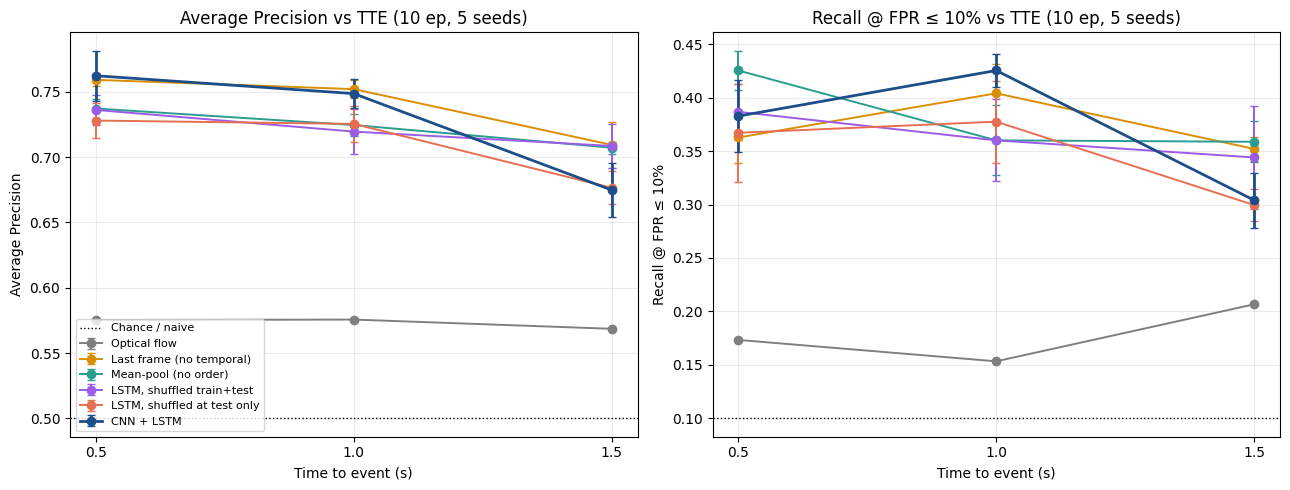

Saved figures with tag: ''


In [13]:
COLOURS = {
    "optical_flow": "#7f7f7f", "last_frame": "#d98e04", "mean_pool": "#2a9d8f",
    "lstm_train_shuffled": "#9b5de5", "lstm_test_shuffled": "#e76f51", "lstm": "#1d4e89",
}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, title in [(axes[0], "AP", "Average Precision"),
                          (axes[1], "Recall@FPR10", "Recall @ FPR ≤ 10%")]:
    for v in ["optical_flow", "last_frame", "mean_pool", "lstm_train_shuffled", "lstm_test_shuffled", "lstm"]:
        sub = summary[summary["variant"] == v].sort_values("tte")
        std = sub[f"{metric}_std"].fillna(0).to_numpy()
        ax.errorbar(sub["tte"], sub[f"{metric}_mean"], yerr=std, marker="o", capsize=3,
                    color=COLOURS[v], label=DISPLAY[v], linewidth=2 if v == "lstm" else 1.4)
    chance = 0.5 if metric == "AP" else 0.10
    ax.axhline(chance, color="black", linestyle=":", linewidth=1, label="Chance / naive")
    ax.set_xticks(TTE_VALUES)
    ax.set_xlabel("Time to event (s)")
    ax.set_ylabel(title)
    ax.set_title(f"{title} vs TTE ({NUM_EPOCHS} ep, 5 seeds)")
    ax.grid(alpha=0.25)
axes[0].legend(fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"temporal_ablation_ap_vs_tte{TAG}.png", dpi=150)
plt.show()
print("Saved figures with tag:", repr(TAG))

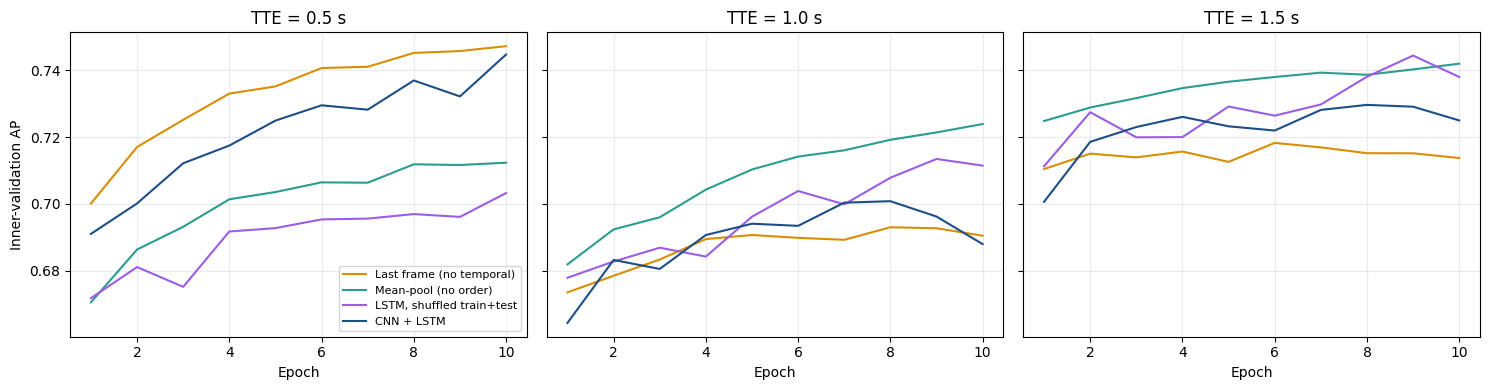

In [14]:
# Learning curves: inner-validation AP (used for epoch selection) per variant, averaged over seeds.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, tte in zip(axes, TTE_VALUES):
    for v in ["last_frame", "mean_pool", "lstm_train_shuffled", "lstm"]:
        curves = np.stack([histories[(v, tte, s)]["inner_AP"].to_numpy() for s in SEEDS])
        ax.plot(range(1, NUM_EPOCHS + 1), curves.mean(0), color=COLOURS[v], label=DISPLAY[v])
    ax.set_title(f"TTE = {tte} s")
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Inner-validation AP")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / f"temporal_ablation_learning_curves{TAG}.png", dpi=150)
plt.show()

## 13. Findings (descriptive; not the final report conclusion)

All numbers are on the 300-video validation set. "±" is the standard deviation over 5 training seeds;
bootstrap intervals (section 11) are over validation clips and are much wider.

**1. Notebook 5 was optimistic.** With the epoch chosen on held-out *training* videos instead of on the
   validation set, CNN + LSTM scores AP 0.762 / 0.749 / 0.675 at 0.5 / 1.0 / 1.5 s, versus 0.793 / 0.774 / 0.739
   in Notebook 5. The `oracle_val_AP` column (best validation epoch, the Notebook 5 protocol) reproduces that
   inflation (0.790 / 0.771 / 0.734). Part of the gap is also the 20% less training data. Use the numbers from this
   notebook in the report.

**2. The learned model clearly beats optical flow.** CNN + LSTM minus optical flow is +0.197, +0.180, +0.117 AP at
   0.5 / 1.0 / 1.5 s, and all three 95% bootstrap intervals exclude zero. Recall at ≤10% false-alarm rate is
   about 0.30–0.43 for the CNN-based models versus 0.15–0.21 for optical flow (chance = 0.10).

**3. We cannot claim that temporal modelling is responsible.** A classifier on the *single last frame* matches
   the LSTM at 0.5 s (0.759 vs 0.762) and 1.0 s (0.752 vs 0.749), and is better at 1.5 s (0.709 vs 0.675, CI of the
   difference just excludes zero). Order-free mean pooling is within the noise at every TTE, as is an LSTM trained on shuffled frames.
   The static ResNet appearance features appear to carry most of the signal.

**4. There is a small trace of order use.** Shuffling frames only at test time lowers the trained LSTM by
   ~0.03 AP at 0.5 s and ~0.02 at 1.0 s (intervals just exclude zero) but not at 1.5 s. This is weak evidence that
   the LSTM exploits some ordering, yet a model trained without order does as well.

**5. Hypothesis check.** The proposal predicted the learned model would degrade *more slowly* than the motion
   baseline. This is **not supported**: CNN + LSTM drops 0.086 AP from 0.5 s to 1.5 s (CI 0.03–0.14), while optical flow is
   flat (−0.007), but flat because it sits near chance at every horizon. The drop from 0.5 s to 1.0 s is not
   distinguishable from zero for any model.

## Caveats

* **Under-training was checked and ruled out.** Re-running everything with `NUM_EPOCHS=30` (outputs tagged `_30ep`) shows
  inner-validation AP peaking around epochs 8–15 and then *falling* for every variant (overfitting; see
  `results/figures/temporal_ablation_learning_curves_30ep.png`). Mean AP is lower at 30 epochs (CNN + LSTM
  0.741 / 0.712 / 0.662) because the longer schedule gives the noisy 240-clip inner validation more chances to pick a bad epoch.
  The conclusions are unchanged: CNN + LSTM beats optical flow by +0.175 / +0.146 / +0.101 AP (all CIs exclude zero); the
  last-frame classifier is not worse than the LSTM at 1.0 s and is better at 1.5 s; the 0.5 s→1.5 s drop for CNN + LSTM is
  0.081 (CI 0.02–0.14). The 10-epoch protocol is therefore kept.
* **No test set.** All numbers are validation numbers. Hyperparameters were not tuned here, but the proposal
  refers to a test set, and none exists yet.
* **Frozen ResNet features, one backbone, one clip configuration.** The conclusion about temporal modelling applies to
  *this* feature extractor and 16-frame sampling.
* Differences of ~0.03 AP are close to the validation-sampling noise (bootstrap 95% intervals on a single AP span ~±0.07).